# Progetto Finale: "ChefBot AI - Dallo scatto alla ricetta"

> "Siete stati assunti da una startup di Food-Tech per sviluppare l'assistente digitale **ChefBot**.
>
> 1. Realizzate un classificatore di immagini che identifichi correttamente il tipo di piatto caricato dall'utente.
> 2. Una volta identificato il piatto, mostrate automaticamente una scheda informativa con ingredienti e valori nutrizionali estratti dal vostro database.
> 3. Implementate una funzione di 'Ricerca per Umore': l'utente scrive una frase (es. 'voglio qualcosa di fresco e leggero') e il sistema propone il piatto più vicino semanticamente tra quelli presenti nel dataset."

L'obiettivo è creare un sistema intelligente capace di colmare il divario tra **pixel** e **conoscenza**. Il sistema deve riconoscere un piatto da una foto e "arricchirlo" con informazioni testuali utili, permettendo anche ricerche basate sul significato semantico.

### Le Sfide Tecniche

**1. Riconoscimento Visivo (Computer Vision)**

Implementare un modello di **Image Classification** sfruttando il **Transfer Learning**.

- **Task:** Utilizzare una base pre-addestrata (es. `MobileNetV2` o `EfficientNetB0`) congelandone i pesi e aggiungendo un classificatore finale personalizzato per le classi di Food101.
- **Obiettivo:** Ottimizzare il modello per riconoscere correttamente almeno un subset di 10-20 classi a scelta.

**2. Knowledge Retrieval (NLP)**

Poiché il dataset fornisce solo immagini e nomi, dovete costruire un "dizionario della conoscenza" (file JSON) che mappi ogni etichetta a dati strutturati.

- **Dati richiesti:** Ingredienti principali, calorie stimate e una breve descrizione.
- **Logica:** Creare una funzione di "lookup" che, data la predizione del modello di visione, recuperi i metadati corrispondenti.

**3. Ricerca Semantica tra i Piatti (Embeddings)**

Implementare un sistema di ricerca che non si basi solo su parole esatte.

- **Esempio:** Se l'utente cerca "dolce con miele", il sistema deve usare gli **embeddings** per calcolare la **similarità coseno** e suggerire piatti come "Baklava" o "Churros", anche se la parola "dolce" non è presente nel nome del piatto.

### Tabella di Marcia del Progetto

| Fase | Cosa è richiesto | Strumento |
|---|---|---|
| **Vision Training** | Fine-tuning di modelli SOTA su dati reali. | `Keras / PyTorch` |
| **Knowledge Mapping** | Creazione di database strutturati per l'arricchimento dati. | `JSON / Python Dict` |
| **Semantic Search** | Rappresentazione vettoriale del testo e distanze. | `Sentence-Transformers / spaCy` |

### Il Dataset: `Food101` (Integrated Version)

Questo dataset è il "gold standard" per la classificazione del cibo. Contiene **101.000 immagini** divise in 101 classi. Utilizzeremo la versione integrata in **TensorFlow Datasets (TFDS)** o **Torchvision**, che automatizza il download, il partizionamento e la gestione della cache.

In [1]:
import os
# Keras 3 sopra PyTorch: così il training usa la GPU anche su Windows
# (TensorFlow nativo su Windows resta in CPU). Va impostato PRIMA di import keras.
os.environ['KERAS_BACKEND'] = 'torch'
# Log di TensorFlow ridotti agli errori critici (come nell'esempio 76)
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
# Windows non supporta i symlink nella cache di Hugging Face: silenziamo l'avviso
os.environ['HF_HUB_DISABLE_SYMLINKS_WARNING'] = '1'

import json
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
import tensorflow_datasets as tfds
import keras

import torch
from transformers import AutoTokenizer, AutoModel
import faiss

In [ ]:
# --- PARAMETRI ---
IMG_SIZE = (224, 224)   # dimensione nativa di MobileNetV2
BATCH_SIZE = 32 #ho una RTX 5050 da 8 GB 
SEED = 42

# Il giro del mondo in 15 piatti di Food101, uno per Paese, con abbastanza varietà
# per la ricerca per mood: dolci, freschi e leggeri, zuppe calde, street food fritto, piatti strani
CLASSI_SCELTE = [
    'baklava',         # Turchia
    'churros',         # Spagna
    'tiramisu',        # Italia
    'escargots',       # Francia
    'takoyaki',        # Giappone
    'poutine',         # Canada
    'ceviche',         # Perù
    'pho',             # Vietnam
    'bibimbap',        # Corea
    'fish_and_chips',  # Regno Unito
    'tacos',           # Messico
    'samosa',          # India
    'greek_salad',     # Grecia
    'falafel',         # Medio Oriente
    'donuts',          # Stati Uniti
]

# Modello per gli embeddings: sfida: la ricerca per umore (es. "something fresh and light"). 
# Scelgo multi-qa-MiniLM-L6-cos-v1 invece # di all-MiniLM-L6-v2 utilizzato negli esercizi perché 
# addestrato su domande e risposte.
EMBEDDING_MODEL = 'sentence-transformers/multi-qa-MiniLM-L6-cos-v1'

# --- PERCORSI (costruiti con os: niente percorsi scritti a mano, 
# come consigliato nella correzione dell'esame precedente) ---
# Cartella del progetto
BASE_DIR = os.getcwd()
DATA_DIR = os.path.join(os.path.expanduser('~'), 'tensorflow_datasets')

KNOWLEDGE_PATH = os.path.join(BASE_DIR, 'chefbot_knowledge.json')
MODEL_PATH = os.path.join(BASE_DIR, 'chefbot_mobilenetv2.keras')

### Roadmap di Sviluppo

#### Fase A: Caricamento del dataset e scelta delle classi

Carichiamo Food101 con `tensorflow_datasets` (codice fornito dalla traccia), in streaming per non saturare la RAM. Il dataset fornisce:
- `image`: tensore dell'immagine (dimensione variabile)
- `label`: numero intero (0-100) mappato alle classi (es. 7 = 'baklava')

Download e caricamento usano percorsi costruiti con `os`, così il notebook si riproduce su qualsiasi macchina:
- il dataset va in `tensorflow_datasets` dentro la cartella home dell'utente (`os.path.expanduser('~')`), fuori dal progetto e da OneDrive;
- la cartella viene creata se manca (`os.makedirs`) e un controllo con `os.path.isdir` dice se Food101 è già su disco o se parte il download (circa 5 GB la prima volta);
- modello e knowledge base si salvano nella cartella del progetto (`os.getcwd()`).

In [3]:
# --- FASE A.1: DOWNLOAD E CARICAMENTO DI FOOD101 ---
# Creo la cartella dei dati se non esiste
os.makedirs(DATA_DIR, exist_ok=True)

# Se Food101 è già su disco lo carico, altrimenti parte il download
food101_presente = os.path.isdir(os.path.join(DATA_DIR, 'food101'))
if food101_presente:
    print(f"Food101 già presente in {DATA_DIR}: caricamento da disco")
else:
    print(f"Food101 non trovato: download in {DATA_DIR} (circa 5 GB, la prima volta richiede tempo)")

# Tre split: il train di Food101 diviso 85/15 in train e validation (usato da EarlyStopping
# e ModelCheckpoint per scegliere il modello), lo split 'validation' di Food101 come test set
# mai visto in training (no data leak)

(ds_train, ds_val, ds_test), ds_info = tfds.load(
    'food101',
    split=['train[:85%]', 'train[85%:]', 'validation'],
    shuffle_files=True,
    as_supervised=True,
    with_info=True,
    data_dir=DATA_DIR,
    download=True
)
print(f"Food101 - train originale: {ds_info.splits['train'].num_examples} immagini "
      f"(85% train, 15% validation) - test: {ds_info.splits['validation'].num_examples} immagini")

Food101 già presente in C:\Users\veron\tensorflow_datasets: caricamento da disco
Food101 - train originale: 75750 immagini (85% train, 15% validation) - test: 25250 immagini


In [4]:
# --- FASE A.2: SCELTA DELLE CLASSI ---
nomi_food101 = ds_info.features['label'].names
print(f"Classi totali in Food101: {len(nomi_food101)}")
print(nomi_food101)

# Controllo: ogni classe scelta deve esistere in Food101 scritta allo stesso modo
for classe in CLASSI_SCELTE:
    assert classe in nomi_food101, f"Classe non trovata in Food101: {classe}"

NUM_CLASSI = len(CLASSI_SCELTE)
print(f"\nClassi scelte: {NUM_CLASSI}")

Classi totali in Food101: 101
['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding', 'breakfast_burrito', 'bruschetta', 'caesar_salad', 'cannoli', 'caprese_salad', 'carrot_cake', 'ceviche', 'cheesecake', 'cheese_plate', 'chicken_curry', 'chicken_quesadilla', 'chicken_wings', 'chocolate_cake', 'chocolate_mousse', 'churros', 'clam_chowder', 'club_sandwich', 'crab_cakes', 'creme_brulee', 'croque_madame', 'cup_cakes', 'deviled_eggs', 'donuts', 'dumplings', 'edamame', 'eggs_benedict', 'escargots', 'falafel', 'filet_mignon', 'fish_and_chips', 'foie_gras', 'french_fries', 'french_onion_soup', 'french_toast', 'fried_calamari', 'fried_rice', 'frozen_yogurt', 'garlic_bread', 'gnocchi', 'greek_salad', 'grilled_cheese_sandwich', 'grilled_salmon', 'guacamole', 'gyoza', 'hamburger', 'hot_and_sour_soup', 'hot_dog', 'huevos_rancheros', 'hummus', 'ice_cream', 'lasagna', 'lobster_bisque', 'lobster_roll_sandwich', 'macaroni_and_

In [5]:
# --- FASE A.3: FILTRO E RIMAPPATURA DELLE ETICHETTE ---
# Indici originali (0-100) delle classi scelte, nell'ordine di CLASSI_SCELTE.
# Le etichette vanno rimappate in 0..NUM_CLASSI-1 perché il layer di uscita Dense ha
# NUM_CLASSI uscite: un'etichetta 97 non avrebbe un'uscita corrispondente e la loss darebbe errore.
# Modello, CLASSI_SCELTE e knowledge base usano così la stessa numerazione.
# Inoltre: layer Dense(15) invece di Dense(101), da 129.381 a 19.215 parametri

indici_originali = tf.constant([nomi_food101.index(c) for c in CLASSI_SCELTE], dtype=tf.int64)

def appartiene_alle_scelte(image, label):
    # True se la label originale è una delle classi scelte
    return tf.reduce_any(tf.equal(label, indici_originali))

def rimappa_label(image, label):
    # La nuova label è la posizione della classe in CLASSI_SCELTE (da 0 a NUM_CLASSI-1)
    nuova_label = tf.argmax(tf.cast(tf.equal(indici_originali, label), tf.int32))
    return image, nuova_label

train_filtrato = ds_train.filter(appartiene_alle_scelte).map(rimappa_label)
val_filtrato = ds_val.filter(appartiene_alle_scelte).map(rimappa_label)
test_filtrato = ds_test.filter(appartiene_alle_scelte).map(rimappa_label)

In [6]:
# --- FASE A.4: PIPELINE tf.data ---
# Accorgimenti per ridurre i tempi:
# 1. filter (A.3): dalla seconda epoca si lavora su ~9.560 immagini di train invece di ~64.400
# 2. resize a 224x224 
# 3. cache(): dalla seconda epoca si salta lettura da disco, decodifica JPEG, filtro e resize
#    (la prima epoca resta lenta: non ho trovato soluzione)
# 4. uint8 in cache: ~2,2 GB in tutto (train + validation + test) invece di ~9 GB in float32
# 5. AUTOTUNE: per gestire al meglio le risorse

def ridimensiona(image, label):
    image = tf.image.resize(image, IMG_SIZE)
    return tf.cast(image, tf.uint8), label

def a_float(image, label):
    return tf.cast(image, tf.float32), label

train_ds = (train_filtrato
            .map(ridimensiona, num_parallel_calls=tf.data.AUTOTUNE)
            .cache()
            .shuffle(1000, seed=SEED)
            .map(a_float, num_parallel_calls=tf.data.AUTOTUNE)
            .batch(BATCH_SIZE)
            .prefetch(tf.data.AUTOTUNE))

val_ds = (val_filtrato
          .map(ridimensiona, num_parallel_calls=tf.data.AUTOTUNE)
          .cache()
          .map(a_float, num_parallel_calls=tf.data.AUTOTUNE)
          .batch(BATCH_SIZE)
          .prefetch(tf.data.AUTOTUNE))

test_ds = (test_filtrato
           .map(ridimensiona, num_parallel_calls=tf.data.AUTOTUNE)
           .cache()
           .map(a_float, num_parallel_calls=tf.data.AUTOTUNE)
           .batch(BATCH_SIZE)
           .prefetch(tf.data.AUTOTUNE))

#### Fase B: Riconoscimento Visivo con Transfer Learning

1. **Backbone:** `MobileNetV2` pre-addestrata su ImageNet, senza il livello superiore (`include_top=False`)
2. **Pesi della base congelati** (`trainable = False`)
3. **Pre-processing:** `preprocess_input` di MobileNetV2, che porta i pixel tra -1 e 1
4. **Classificatore finale personalizzato** con un'uscita per ognuna delle classi scelte

In [7]:
# --- FASE B: ARCHITETTURA ---
def build_chefbot_model(num_classi):
    # Base pre-addestrata su ImageNet, senza il classificatore originale a 1000 classi
    base_model = keras.applications.MobileNetV2(
        weights='imagenet',
        include_top=False,
        input_shape=IMG_SIZE + (3,)
    )
    base_model.trainable = False  # pesi della base congelati

    inputs = keras.Input(shape=IMG_SIZE + (3,))
    # Data augmentation: attiva solo durante il training, spenta in predict
    x = keras.layers.RandomFlip('horizontal')(inputs)
    x = keras.layers.RandomRotation(0.1)(x)
    x = keras.layers.Rescaling(1./127.5, offset=-1)(x)
    # training=False: i BatchNormalization della base restano in modalità inferenza 
    # per evitare catastrophic forgetting 
    x = base_model(x, training=False)
    x = keras.layers.GlobalAveragePooling2D()(x)
    x = keras.layers.Dropout(0.2)(x)
    outputs = keras.layers.Dense(num_classi, activation='softmax')(x)

    return keras.Model(inputs, outputs), base_model

model, base_model = build_chefbot_model(NUM_CLASSI)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 15)             │        19,215 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,277,199 (8.69 MB)

 Trainable params: 19,215 (75.06 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

#### Fase C: Compilazione e Training

In [8]:
# --- FASE C: COMPILAZIONE ---
# Classi da 0..N-1 scelgo sparse_categorical_crossentropy
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [9]:
# --- FASE C: CALLBACKS ---
# Si ferma se la val_loss non migliora per 3 epoche e ripristina i pesi migliori
early_stopping = keras.callbacks.EarlyStopping(monitor='val_loss',
                                               patience=3,
                                               restore_best_weights=True)

# Salva su disco il modello migliore (che è il file che userà Flask)
checkpoint = keras.callbacks.ModelCheckpoint(MODEL_PATH,
                                             monitor='val_loss',
                                             save_best_only=True)

In [10]:
# --- FASE C: TRAINING ---
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[early_stopping, checkpoint]
)

c:\Users\veron\miniconda3\envs\epicode-io\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/15
    298/Unknown 62s 197ms/step - accuracy: 0.6072 - loss: 1.2753

c:\Users\veron\miniconda3\envs\epicode-io\Lib\site-packages\keras\src\trainers\epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


298/298 ━━━━━━━━━━━━━━━━━━━━ 69s 221ms/step - accuracy: 0.6072 - loss: 1.2753 - val_accuracy: 0.7613 - val_loss: 0.7954
Epoch 2/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 52s 173ms/step - accuracy: 0.7415 - loss: 0.8227 - val_accuracy: 0.7822 - val_loss: 0.7041
Epoch 3/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 53s 176ms/step - accuracy: 0.7671 - loss: 0.7349 - val_accuracy: 0.7979 - val_loss: 0.6669
Epoch 4/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 53s 176ms/step - accuracy: 0.7853 - loss: 0.6700 - val_accuracy: 0.7927 - val_loss: 0.6687
Epoch 5/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 48s 162ms/step - accuracy: 0.7905 - loss: 0.6438 - val_accuracy: 0.7991 - val_loss: 0.6603
Epoch 6/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 50s 169ms/step - accuracy: 0.8013 - loss: 0.6331 - val_accuracy: 0.8043 - val_loss: 0.6450
Epoch 7/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 48s 160ms/step - accuracy: 0.8113 - loss: 0.5991 - val_accuracy: 0.8072 - val_loss: 0.6398
Epoch 8/15
298/298 ━━━━━━━━━━━━━━━━━━━━ 48s 161ms/step - accuracy: 0.8101 - loss: 0.5913 - val

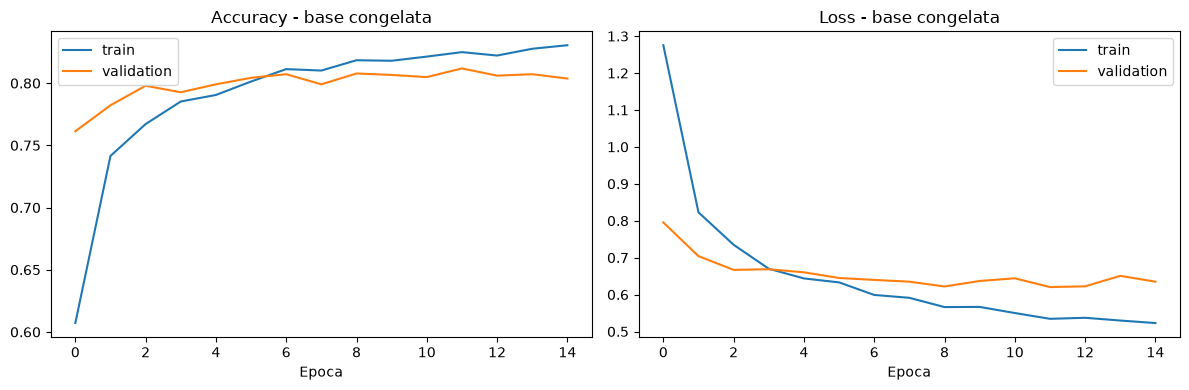

In [11]:
# --- FASE C: CURVE DI TRAINING ---
def mostra_curve(h, titolo):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(h.history['accuracy'], label='train')
    ax1.plot(h.history['val_accuracy'], label='validation')
    ax1.set_title(f'Accuracy - {titolo}')
    ax1.set_xlabel('Epoca')
    ax1.legend()

    ax2.plot(h.history['loss'], label='train')
    ax2.plot(h.history['val_loss'], label='validation')
    ax2.set_title(f'Loss - {titolo}')
    ax2.set_xlabel('Epoca')
    ax2.legend()

    plt.tight_layout()
    plt.show()

mostra_curve(history, 'base congelata')

#### Fase C.2: Fine-tuning

Con la testa già addestrata sblocchiamo gli ultimi strati di MobileNetV2 e li riaddestriamo con un learning rate molto basso, per adattare le feature di ImageNet al cibo senza distruggerle.

Epoch 16/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 55s 183ms/step - accuracy: 0.8363 - loss: 0.5006 - val_accuracy: 0.8177 - val_loss: 0.6055
Epoch 17/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 53s 179ms/step - accuracy: 0.8524 - loss: 0.4416 - val_accuracy: 0.8217 - val_loss: 0.5931
Epoch 18/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 54s 180ms/step - accuracy: 0.8665 - loss: 0.4149 - val_accuracy: 0.8322 - val_loss: 0.5653
Epoch 19/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 56s 187ms/step - accuracy: 0.8768 - loss: 0.3766 - val_accuracy: 0.8316 - val_loss: 0.5747
Epoch 20/20
298/298 ━━━━━━━━━━━━━━━━━━━━ 51s 172ms/step - accuracy: 0.8841 - loss: 0.3583 - val_accuracy: 0.8461 - val_loss: 0.5324


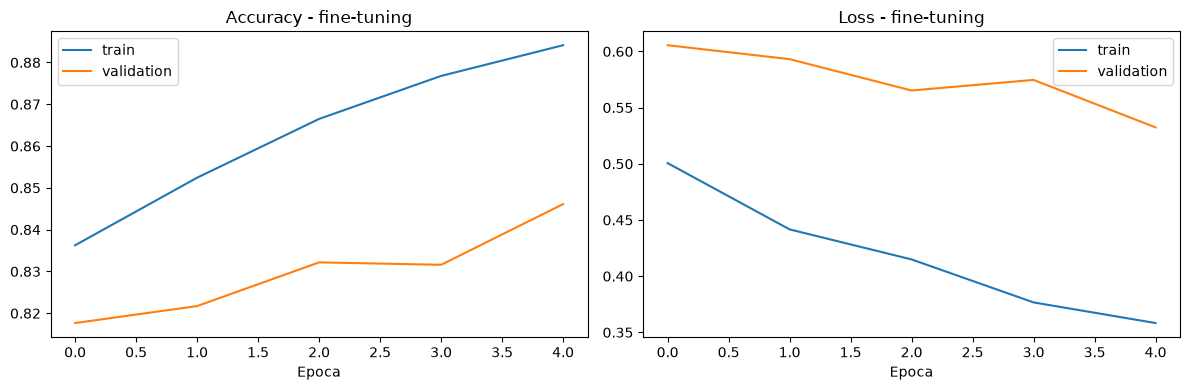

In [12]:
# --- FASE C.2: FINE-TUNING ---
# Sblocco la base, poi blocco i primi 100 strati (su 154): 
base_model.trainable = True
for layer in base_model.layers[:100]:
    layer.trainable = False
# Le BatchNormalization della parte sbloccata restano congelate: con trainable=False
# Keras le fa girare sempre in modalità inferenza (statistiche di ImageNet).
for layer in base_model.layers[100:]:
    if isinstance(layer, keras.layers.BatchNormalization):
        layer.trainable = False

# learning rate 100 volte più basso
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

epoca_partenza = len(history.history['loss'])
history_fine = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epoca_partenza + 5,
    initial_epoch=epoca_partenza,
    callbacks=[early_stopping, checkpoint]
)

mostra_curve(history_fine, 'fine-tuning')

#### Fase D: Valutazione del classificatore

Accuratezza sul test set (lo split `validation` di Food101, mai visto durante il training né usato per scegliere il modello), report per classe e matrice di confusione.

In [13]:
# --- FASE D: VALUTAZIONE ---
# Ricarico dal disco il modello migliore salvato dal checkpoint (val_loss più bassa
# tra base congelata e fine-tuning): quello in memoria è l'ultimo dell'addestramento
model = keras.models.load_model(MODEL_PATH)

loss, acc = model.evaluate(test_ds, verbose=0)
print(f"[RISULTATO] Accuratezza sul test set: {acc*100:.2f}%\n")

# Etichette reali e predette 
y_true = np.concatenate([y.numpy() for _, y in test_ds])
y_pred = np.argmax(model.predict(test_ds, verbose=0), axis=1)

print(classification_report(y_true, y_pred, target_names=CLASSI_SCELTE))

[RISULTATO] Accuratezza sul test set: 87.47%

                precision    recall  f1-score   support

       baklava       0.91      0.88      0.90       250
       churros       0.91      0.89      0.90       250
      tiramisu       0.86      0.91      0.88       250
     escargots       0.91      0.94      0.92       250
      takoyaki       0.86      0.88      0.87       250
       poutine       0.87      0.92      0.89       250
       ceviche       0.77      0.74      0.76       250
           pho       0.95      0.98      0.96       250
      bibimbap       0.93      0.92      0.92       250
fish_and_chips       0.88      0.91      0.89       250
         tacos       0.80      0.78      0.79       250
        samosa       0.93      0.81      0.87       250
   greek_salad       0.82      0.88      0.85       250
       falafel       0.86      0.76      0.80       250
        donuts       0.87      0.92      0.89       250

      accuracy                           0.87      3750


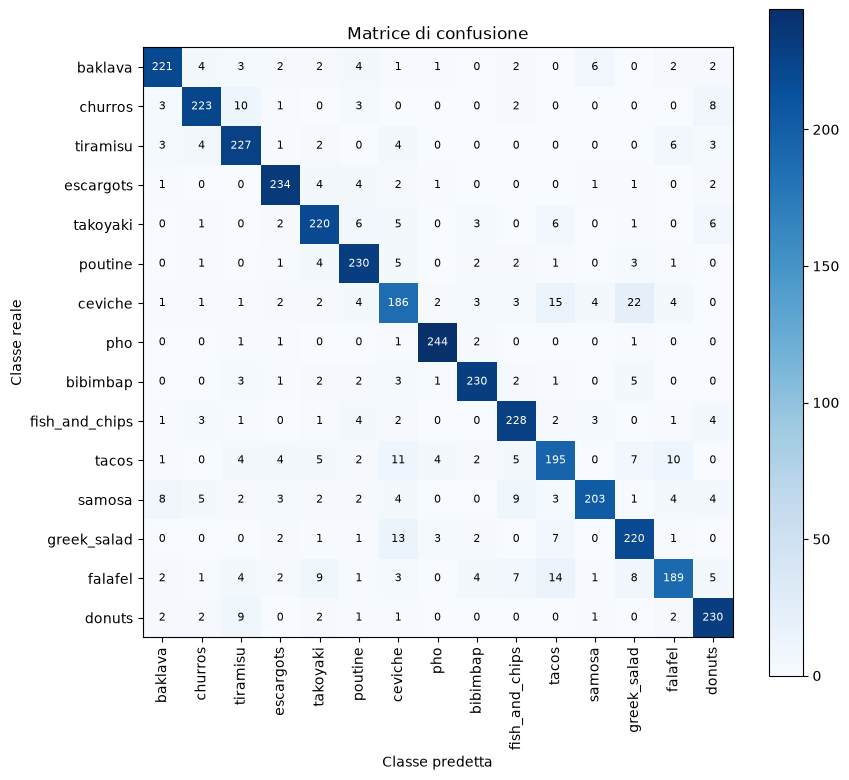

In [14]:
# --- FASE D: MATRICE DI CONFUSIONE ---
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(NUM_CLASSI))
ax.set_xticklabels(CLASSI_SCELTE, rotation=90)
ax.set_yticks(range(NUM_CLASSI))
ax.set_yticklabels(CLASSI_SCELTE)
ax.set_xlabel('Classe predetta')
ax.set_ylabel('Classe reale')
ax.set_title('Matrice di confusione')
for i in range(NUM_CLASSI):
    for j in range(NUM_CLASSI):
        ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=8,
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.colorbar(im)
plt.tight_layout()
plt.show()

In [ ]:
# Analisi sulla base della conoscenza di dominio: 
# gli errori non sono casuali, il modello confonde piatti che si somigliano visivamente.
# - ceviche <-> greek_salad (22 + 13) e ceviche <-> tacos (15 + 11): ciotole fresche e colorate
#   con verdure crude, cipolla rossa, coriandolo e lime
# - falafel <-> tacos (14 + 10): ripieni in un involucro morbido (pita o tortilla) con salse
# - falafel -> takoyaki (9): palline marroni fritte
# - churros/donuts -> tiramisu (10, 9) e churros -> donuts (8): dolci fritti, zucchero, cioccolato
# - samosa -> fish_and_chips (9) e samosa -> baklava (8): crosta di pasta dorata
# Il pho è la classe più riconoscibile (244/250): una ciotola di brodo con noodles.
# Ceviche, tacos e falafel sono le classi più deboli (f1 0.76-0.80): servirebbero più immagini
# o un fine-tuning più profondo per distinguere i dettagli.


#### Fase E: Knowledge Mapping

Costruiamo il "dizionario della conoscenza": per ogni classe scelta **ingredienti principali**, **calorie stimate** e una **breve descrizione**. Lo salviamo in JSON e scriviamo la funzione di lookup che, data la predizione del modello di visione, recupera la scheda del piatto.

In [ ]:
# --- FASE E.1: DIZIONARIO DELLA CONOSCENZA ---
# Una chiave per ogni nome in CLASSI_SCELTE, scritta esattamente come in Food101.
# Calorie: stime indicative per la porzione indicata in 'serving'
# Mood: parole chiave sull'esperienza del piatto, usate dalla ricerca per mood (Fase F)
# Dizionario creato con LLM 
knowledge_base = {
    'baklava': {
        'ingredients': ['phyllo dough', 'walnuts', 'pistachios', 'butter', 'honey', 'sugar syrup', 'cinnamon'],
        'serving': '1 piece (about 60 g)',
        'calories_kcal': 250,
        'description': 'Turkish layered pastry made of thin phyllo sheets filled with chopped nuts and soaked in sweet honey syrup.',
        'mood': 'sweet, honey, nutty, dessert',
    },
    'churros': {
        'ingredients': ['flour', 'water', 'butter', 'eggs', 'sugar', 'cinnamon', 'frying oil'],
        'serving': '3 churros (about 100 g)',
        'calories_kcal': 350,
        'description': 'Spanish fried dough sticks, crispy outside and soft inside, rolled in cinnamon sugar and dipped in hot chocolate.',
        'mood': 'sweet, fried, crispy, dessert, snack',
    },
    'tiramisu': {
        'ingredients': ['ladyfingers', 'mascarpone', 'eggs', 'sugar', 'espresso coffee', 'cocoa powder'],
        'serving': '1 slice (about 150 g)',
        'calories_kcal': 450,
        'description': 'Italian creamy dessert of coffee-soaked ladyfingers layered with mascarpone cream and dusted with cocoa.',
        'mood': 'sweet, creamy, coffee, dessert',
    },
    'escargots': {
        'ingredients': ['land snails', 'butter', 'garlic', 'parsley', 'shallots', 'white wine'],
        'serving': '6 snails with garlic butter',
        'calories_kcal': 300,
        'description': 'French delicacy of snails baked in their shells with garlic and parsley butter, an unusual and exotic appetizer.',
        'mood': 'weird, exotic, adventurous, unusual, garlic',
    },
    'takoyaki': {
        'ingredients': ['wheat flour batter', 'diced octopus', 'tempura scraps', 'pickled ginger', 'green onion', 'takoyaki sauce', 'mayonnaise', 'bonito flakes'],
        'serving': '6 balls (about 150 g)',
        'calories_kcal': 280,
        'description': 'Japanese street food: hot round batter balls filled with octopus, topped with savory sauce, mayo and dancing bonito flakes.',
        'mood': 'street food, weird, exotic, adventurous, octopus, hot',
    },
    'poutine': {
        'ingredients': ['french fries', 'cheese curds', 'brown gravy'],
        'serving': '1 portion (about 350 g)',
        'calories_kcal': 740,
        'description': 'Canadian comfort food of crispy fries topped with squeaky cheese curds and hot brown gravy, heavy and indulgent.',
        'mood': 'heavy, cheesy, comfort food, hot, fried',
    },
    'ceviche': {
        'ingredients': ['raw white fish', 'lime juice', 'red onion', 'chili pepper', 'coriander'],
        'serving': '1 bowl (about 200 g)',
        'calories_kcal': 200,
        'description': 'Peruvian dish of raw fish cured in citrus juice with onion, chili and coriander, served cold, zesty and light.',
        'mood': 'fresh, light, cold, summer, raw fish, citrus',
    },
    'pho': {
        'ingredients': ['rice noodles', 'beef broth', 'thinly sliced beef', 'star anise', 'cinnamon', 'fresh herbs', 'bean sprouts', 'lime'],
        'serving': '1 bowl (about 700 g)',
        'calories_kcal': 450,
        'description': 'Vietnamese hot noodle soup with an aromatic beef broth, rice noodles and herbs, warming and comforting.',
        'mood': 'warm, hot soup, cozy, winter, comforting',
    },
    'bibimbap': {
        'ingredients': ['steamed rice', 'sauteed vegetables', 'beef', 'fried egg', 'gochujang chili paste', 'sesame oil'],
        'serving': '1 bowl (about 500 g)',
        'calories_kcal': 600,
        'description': 'Korean mixed rice bowl topped with colorful vegetables, beef, a fried egg and spicy chili paste.',
        'mood': 'spicy, healthy, colorful, rice bowl',
    },
    'fish_and_chips': {
        'ingredients': ['battered cod', 'potatoes', 'frying oil', 'malt vinegar', 'salt', 'tartar sauce'],
        'serving': '1 portion (about 400 g)',
        'calories_kcal': 850,
        'description': 'British pub classic of deep-fried battered fish with thick chips, crispy, salty and filling.',
        'mood': 'fried, crispy, salty, heavy, pub food',
    },
    'tacos': {
        'ingredients': ['corn tortillas', 'seasoned meat', 'onion', 'coriander', 'salsa', 'lime'],
        'serving': '3 tacos (about 300 g)',
        'calories_kcal': 500,
        'description': 'Mexican street food of soft corn tortillas filled with seasoned meat, fresh salsa, onion and coriander, spicy and colorful.',
        'mood': 'spicy, street food, colorful, party',
    },
    'samosa': {
        'ingredients': ['pastry dough', 'potatoes', 'peas', 'onion', 'cumin', 'garam masala', 'chili pepper', 'frying oil'],
        'serving': '2 pieces (about 120 g)',
        'calories_kcal': 310,
        'description': 'Indian fried triangular pastry stuffed with spiced potatoes and peas, crunchy and fragrant.',
        'mood': 'fried, crispy, spicy, vegetarian, snack',
    },
    'greek_salad': {
        'ingredients': ['tomatoes', 'cucumber', 'red onion', 'feta cheese', 'kalamata olives', 'olive oil', 'oregano'],
        'serving': '1 bowl (about 250 g)',
        'calories_kcal': 250,
        'description': 'Refreshing Greek salad of raw crunchy vegetables, feta cheese and olives, cold, light and healthy.',
        'mood': 'fresh, light, cold, summer, healthy, vegetarian',
    },
    'falafel': {
        'ingredients': ['chickpeas', 'onion', 'garlic', 'parsley', 'coriander', 'cumin', 'frying oil'],
        'serving': '5 balls (about 100 g)',
        'calories_kcal': 330,
        'description': 'Middle Eastern deep-fried balls of ground chickpeas and herbs, vegetarian, crunchy outside and served in pita with tahini.',
        'mood': 'vegetarian, fried, crispy, street food',
    },
    'donuts': {
        'ingredients': ['flour', 'sugar', 'eggs', 'milk', 'yeast', 'butter', 'sugar glaze', 'sprinkles'],
        'serving': '1 glazed donut (about 70 g)',
        'calories_kcal': 260,
        'description': 'American ring-shaped fried sweet dough covered with sugary glaze and colorful sprinkles.',
        'mood': 'sweet, sugary, fun, colorful, snack',
    },
}

# Controllo: stesse classi e stesso ordine del modello (Flask ricava l'ordine da qui)
assert list(knowledge_base) == CLASSI_SCELTE

In [16]:
# --- FASE E.2: SALVATAGGIO IN JSON ---
with open(KNOWLEDGE_PATH, 'w', encoding='utf-8') as f:
    json.dump(knowledge_base, f, ensure_ascii=False, indent=2)

# Controllo il database richiesto dalla traccia, che vieno letto da Flask
with open(KNOWLEDGE_PATH, encoding='utf-8') as f:
    knowledge_base = json.load(f)
print(f"Salvato {KNOWLEDGE_PATH}: {len(knowledge_base)} piatti")

Salvato c:\Users\veron\OneDrive\Documenti\EPICODE\Modulo 5\chefbot_knowledge.json: 15 piatti


In [17]:
# --- FASE E.3: FUNZIONE DI LOOKUP ---
def cerca_scheda(nome_piatto):
    # Data la classe predetta dal modello di visione, restituisce i suoi metadati (None se manca)
    return knowledge_base.get(nome_piatto)

def mostra_scheda(nome_piatto, confidenza=None):
    scheda = cerca_scheda(nome_piatto)
    if scheda is None:
        print(f"Nessuna scheda per '{nome_piatto}'")
        return
    titolo = nome_piatto.replace('_', ' ').title()
    if confidenza is not None:
        titolo += f"  (confidenza {confidenza:.1%})"
    print('=' * 60)
    print(titolo)
    print('=' * 60)
    print(scheda['description'])
    print(f"\nIngredients: {', '.join(scheda['ingredients'])}")
    print(f"Calories:    ~{scheda['calories_kcal']} kcal per {scheda['serving']}")
    print(f"Mood:        {scheda['mood']}")

mostra_scheda('takoyaki')

Takoyaki
Japanese street food: hot round batter balls filled with octopus, topped with savory sauce, mayo and dancing bonito flakes.

Ingredients: wheat flour batter, diced octopus, tempura scraps, pickled ginger, green onion, takoyaki sauce, mayonnaise, bonito flakes
Calories:    ~280 kcal per 6 balls (about 150 g)
Mood:        street food, weird, exotic, adventurous, octopus, hot


#### Fase F: Ricerca per Umore (Ricerca Semantica)

Ci basiamo sull'esempio 76 del corso (Ricerca Semantica e Vector Database).
1. Trasformiamo in embeddings il testo di ogni piatto del dizionario
2. Normalizziamo i vettori e li indicizziamo con FAISS
3. Trasformiamo la frase dell'utente con lo stesso embedder e cerchiamo i piatti più vicini

In [ ]:
# --- FASE F.1: EMBEDDER 
class SimpleEmbedder:
    def __init__(self, model_name):
        print(f"Caricamento del modello Hugging Face in corso: {model_name}...")
        # Il tokenizer converte il testo in ID numerici, il modello li trasforma in vettori
        self.tokenizer = AutoTokenizer.from_pretrained(model_name)
        self.model = AutoModel.from_pretrained(model_name)
        # Modalità valutazione: niente Dropout, risultati deterministici
        self.model.eval()

    def encode(self, texts):
        # Fase 1: tokenizzazione (padding e truncation per avere frasi della stessa lunghezza)
        inputs = self.tokenizer(texts, padding=True, truncation=True, return_tensors='pt')

        # Fase 2: inferenza senza calcolo dei gradienti
        with torch.no_grad():
            outputs = self.model(**inputs)

        # Fase 3: mean pooling, media dei vettori dei token escludendo il padding
        token_embeddings = outputs.last_hidden_state
        attention_mask = inputs['attention_mask']
        input_mask_expanded = attention_mask.unsqueeze(-1).expand(token_embeddings.size()).float()
        sum_embeddings = torch.sum(token_embeddings * input_mask_expanded, 1)
        sum_mask = torch.clamp(input_mask_expanded.sum(1), min=1e-9)
        embeddings = sum_embeddings / sum_mask

        # Array NumPy per FAISS
        return embeddings.numpy()

embedder = SimpleEmbedder(EMBEDDING_MODEL)

Caricamento del modello Hugging Face in corso: sentence-transformers/multi-qa-MiniLM-L6-cos-v1...


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

In [24]:
# --- FASE F.2: CORPUS DEI PIATTI E INDICE FAISS ---
# Dato che la sfida è cercare i piatti per umore uso description e mood; aggiungo in fondo
# gli ingredienti perché l'esempio nella consegna della traccia ('dolce con miele') mescola 
# umore e ingrediente.

nomi_piatti = list(knowledge_base.keys())
testi_piatti = [
    f"{scheda['description']} Mood: {scheda['mood']}. Ingredients: {', '.join(scheda['ingredients'])}."
    for scheda in knowledge_base.values()
]

emb_piatti = embedder.encode(testi_piatti)

# Vettori normalizzati: con IndexFlatIP il prodotto scalare diventa la similarità coseno
faiss.normalize_L2(emb_piatti)
indice_faiss = faiss.IndexFlatIP(emb_piatti.shape[1])
indice_faiss.add(emb_piatti)
print(f"Piatti indicizzati: {indice_faiss.ntotal} - dimensione embeddings: {emb_piatti.shape[1]}")

Piatti indicizzati: 15 - dimensione embeddings: 384


In [26]:
# --- FASE F.3: FUNZIONE DI RICERCA PER UMORE ---
def ricerca_per_umore(frase, k=3):
    vettore = embedder.encode([frase])
    faiss.normalize_L2(vettore)
    punteggi, indici = indice_faiss.search(vettore, k)
    return [(nomi_piatti[i], float(s)) for s, i in zip(punteggi[0], indici[0])]

In [28]:
# --- FASE F.4: TEST ---
frasi_test = [
    'I want something fresh and light',
    'a sweet dessert with honey',
    'something warm for a cold winter evening',
    'a crispy fried street food snack',
    'something spicy',
    'I feel adventurous: something weird and exotic',
    'I feel like eating raw fish',
    'something with chickpeas',
    'a dessert with coffee',
    'something with cinnamon',
]

for frase in frasi_test:
    print(f"\nRicerca: '{frase}'")
    for pos, (piatto, score) in enumerate(ricerca_per_umore(frase), start=1):
        print(f"  {pos}. {piatto:<15} similarità {score:.4f}")


Ricerca: 'I want something fresh and light'
  1. greek_salad     similarità 0.2576
  2. donuts          similarità 0.2067
  3. churros         similarità 0.1845

Ricerca: 'a sweet dessert with honey'
  1. baklava         similarità 0.4379
  2. tiramisu        similarità 0.3566
  3. greek_salad     similarità 0.3176

Ricerca: 'something warm for a cold winter evening'
  1. poutine         similarità 0.3090
  2. pho             similarità 0.2511
  3. greek_salad     similarità 0.2320

Ricerca: 'a crispy fried street food snack'
  1. takoyaki        similarità 0.5857
  2. fish_and_chips  similarità 0.5732
  3. poutine         similarità 0.4928

Ricerca: 'something spicy'
  1. bibimbap        similarità 0.4912
  2. ceviche         similarità 0.4510
  3. takoyaki        similarità 0.4221

Ricerca: 'I feel adventurous: something weird and exotic'
  1. takoyaki        similarità 0.2329
  2. escargots       similarità 0.2189
  3. churros         similarità 0.1806

Ricerca: 'I feel like eating

#### Fase G: ChefBot completo — dallo scatto alla ricetta

Una foto in ingresso: il modello riconosce il piatto e il sistema mostra la scheda informativa.


Piatto reale: tiramisu


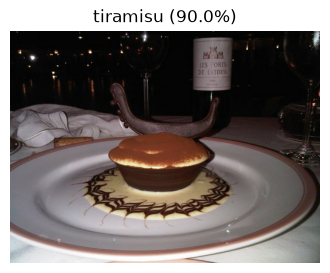

Alternative: churros 6.8%, escargots 2.1%
Tiramisu  (confidenza 90.0%)
Italian creamy dessert of coffee-soaked ladyfingers layered with mascarpone cream and dusted with cocoa.

Ingredients: ladyfingers, mascarpone, eggs, sugar, espresso coffee, cocoa powder
Calories:    ~450 kcal per 1 slice (about 150 g)
Mood:        sweet, creamy, coffee, dessert

Piatto reale: greek_salad


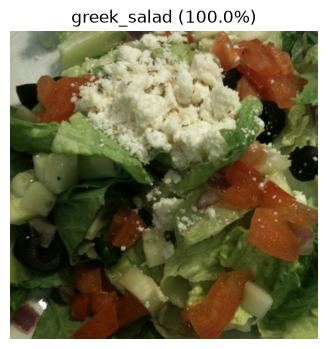

Alternative: falafel 0.0%, ceviche 0.0%
Greek Salad  (confidenza 100.0%)
Refreshing Greek salad of raw crunchy vegetables, feta cheese and olives, cold, light and healthy.

Ingredients: tomatoes, cucumber, red onion, feta cheese, kalamata olives, olive oil, oregano
Calories:    ~250 kcal per 1 bowl (about 250 g)
Mood:        fresh, light, cold, summer, healthy, vegetarian

Piatto reale: takoyaki


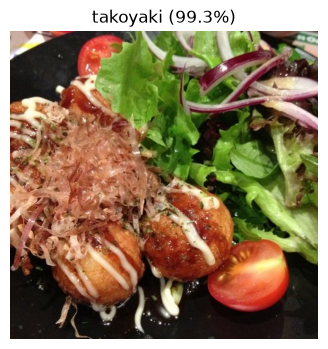

Alternative: bibimbap 0.2%, fish_and_chips 0.2%
Takoyaki  (confidenza 99.3%)
Japanese street food: hot round batter balls filled with octopus, topped with savory sauce, mayo and dancing bonito flakes.

Ingredients: wheat flour batter, diced octopus, tempura scraps, pickled ginger, green onion, takoyaki sauce, mayonnaise, bonito flakes
Calories:    ~280 kcal per 6 balls (about 150 g)
Mood:        street food, weird, exotic, adventurous, octopus, hot


In [29]:
# --- FASE G: FOTO -> PIATTO -> SCHEDA ---
def chefbot(immagine, top_k=3):
    # immagine: array (altezza, larghezza, 3) con pixel 0-255, di qualsiasi dimensione
    x = tf.image.resize(immagine, IMG_SIZE).numpy()
    probs = model.predict(np.expand_dims(x, axis=0), verbose=0)[0]
    migliori = np.argsort(probs)[::-1][:top_k]
    piatto = CLASSI_SCELTE[migliori[0]]

    plt.figure(figsize=(4, 4))
    plt.imshow(np.asarray(immagine).astype('uint8'))
    plt.title(f"{piatto} ({probs[migliori[0]]:.1%})")
    plt.axis('off')
    plt.show()

    print('Alternative: ' + ', '.join(f"{CLASSI_SCELTE[i]} {probs[i]:.1%}" for i in migliori[1:]))
    mostra_scheda(piatto, probs[migliori[0]])

# Prova su 3 immagini originali del test set (non ridimensionate)
for immagine, label in test_filtrato.take(3):
    print(f"\nPiatto reale: {CLASSI_SCELTE[int(label)]}")
    chefbot(immagine.numpy())

# Uso con una foto qualsiasi (jpg/png di uno dei 15 piatti):
# foto = keras.utils.img_to_array(keras.utils.load_img('percorso/della/foto.jpg'))
# chefbot(foto)


#### Fase H: Deployment con Flask

File dell'applicazione: `Progetto_ChefBot_app.py`.

In [30]:
# --- FASE H: FILE PER IL DEPLOYMENT ---
# Il modello migliore è già su disco (salvato dal ModelCheckpoint durante il training):
# controllo che i due file usati dall'app Flask esistano
for percorso in [MODEL_PATH, KNOWLEDGE_PATH]:
    assert os.path.exists(percorso), f"File mancante: {percorso}"
    print(f"{os.path.basename(percorso)}: {os.path.getsize(percorso) / 1e6:.1f} MB")

print("Per l'app: python Progetto_ChefBot_app.py")


chefbot_mobilenetv2.keras: 24.6 MB
chefbot_knowledge.json: 0.0 MB
Per l'app: python Progetto_ChefBot_app.py
